In [ ]:
import pathlib

import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib.theory._calc_denovo_fixprob import calc_denovo_fixprob
from pylib.theory._calc_selection_from_num_sweeps import (
    calc_selection_from_num_sweeps,
)

In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-11-25T15:59:38.447849+00:00

Python implementation: CPython
Python version       : 3.10.12
IPython version      : 7.31.1

Compiler    : GCC 11.4.0
OS          : Linux
Release     : 6.8.0-1070-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

matplotlib: 3.9.2
teeplot   : 1.2.0
seaborn   : 0.13.2
pandas    : 2.2.3
marimo    : 0.23.2
numpy     : 2.1.2
scipy     : 1.14.1

```

In [ ]:
teeplot_subdir = pathlib.Path(__file__).stem
teeplot_subdir

'callens2023-hypermutator-emergence'

# Applying the *de novo* mutator model to Callens et al. (2023)

[Callens et al. (2023)](https://doi.org/10.1093/evlett/qrad019) evolved 95 *E. coli* populations for ~1,000 generations under antibiotic stress, osmotic stress, or no stress, and tracked emergence of hypermutators.
Hypermutators emerged more often under osmotic stress, where more loci contribute to adaptation (43, versus 23 under antibiotic stress).

Here we ask what the well-mixed *de novo* model (`calc_denovo_fixprob`) predicts for the probability that a hypermutator has fixed by the end of that experiment.

## Approach

The model's parameters were chosen for the simulations in this repository, not for this experiment, so we set as many as possible from the experiment itself.

- **Population size** $N$: bottleneck size from optical density, times generations per transfer, times $\ln 2$.
- **Duration**: 148 transfers at $\log_2 100 \approx 6.64$ generations each.
- **Adaptive potential** $K$: number of loci inferred to contribute to adaptation (Callens et al. Figure 2D). None is reported for the control, so it is treated as not limiting.
- **Model clock** $s$: the model's selection strength is set so that nonmutators complete as many selective sweeps as the median number of mutations observed to fix in populations that stayed nonmutator (`calc_selection_from_num_sweeps`).

That leaves the supply rate of hypermutators $\mu$, which the experiment does not measure.
We show predictions across three orders of magnitude of $\mu$ rather than fit it.
Remaining parameters keep their defaults: beneficial mutation rate $U_b = 10^{-6}$, deleterious mutation rate $U_d = 10^{-4}$, and 100-fold mutator strength.

## Prep Data

Tables are derived from the public-domain Dryad deposit, <https://doi.org/10.5061/dryad.hqbzkh1mr>; see `data/callens2023/README.md`.

In [ ]:
data_dir = pathlib.Path(__file__).parent.parent / "data" / "callens2023"
df_populations = pd.read_csv(data_dir / "populations.csv")
df_is10 = pd.read_csv(data_dir / "is10_pcr.csv")
df_od = pd.read_csv(data_dir / "optical_density.csv")

In [ ]:
df_populations

,population,stress,stress level,num mutations,num fixed mutations,mutator allele frequency,mutator allele genes
0,A40.1,antibiotic,40%,21,13,0.0,NaN
1,A40.10,antibiotic,40%,30,3,0.0,NaN
2,A40.11,antibiotic,40%,17,1,0.0,NaN
3,A40.12,antibiotic,40%,18,4,0.0,NaN
4,A40.2,antibiotic,40%,32,0,0.0,NaN
...,...,...,...,...,...,...,...
87,O60.5,osmotic,60%,82,8,0.0,NaN
88,O60.6,osmotic,60%,43,7,0.0,NaN
89,O60.7,osmotic,60%,33,17,0.0,NaN
90,O60.8,osmotic,60%,325,79,1.0,mutH


In [ ]:
df_is10[df_is10["first detected transfer"].notna()]

,population,stress,stress level,gene,num assays,first detected transfer,first fixed transfer,final transfer,final status
24,A3.1,antibiotic,60%,mutS,15,88.5,NaN,137.9,WT
36,S1.1,osmotic,20%,mutS,14,52.0,72.5,148.0,MutS IS
37,S1.2,osmotic,20%,mutS,16,99.5,NaN,148.0,WT + MutS IS
40,S1.5,osmotic,20%,mutS,21,40.0,72.5,148.0,MutS IS
42,S1.7,osmotic,20%,mutS,15,117.5,NaN,148.0,WT + MutS IS
...,...,...,...,...,...,...,...,...,...
58,S2.11,osmotic,40%,mutS,10,72.5,137.9,148.0,MutS IS
60,S3.2,osmotic,60%,mutS,12,23.0,72.5,137.9,MutS IS
62,S3.4,osmotic,60%,mutS,10,72.5,137.9,148.0,MutS IS
99,A1.5,antibiotic,20%,mutL,16,119.0,NaN,148.0,WT + MutL IS


In [ ]:
df_od

,stress,stress level,OD600 mean,OD600 std,OD600 count
0,antibiotic,20%,1.0527,0.1478,576
1,antibiotic,40%,0.9737,0.1822,576
2,antibiotic,60%,0.8461,0.2490,576
3,control,NaN,1.2401,0.1198,1152
4,osmotic,20%,0.8633,0.2104,576
5,osmotic,40%,0.7590,0.2630,576
6,osmotic,60%,0.7386,0.2495,558


## Observed Outcomes

A population is counted as hypermutator-fixed if a non-synonymous, indel, or insertion sequence mutation in a known mutator gene reached frequency 0.9 by generation 1,000.

In [ ]:
stresses = ["control", "antibiotic", "osmotic"]
df_populations["is hypermutator"] = (
    df_populations["mutator allele frequency"] > 0
)
df_populations["is hypermutator fixed"] = (
    df_populations["mutator allele frequency"] >= 0.9
)
df_observed = (
    df_populations.groupby("stress")
    .agg(
        **{
            "num populations": ("population", "size"),
            "num emerged": ("is hypermutator", "sum"),
            "num fixed": ("is hypermutator fixed", "sum"),
        },
    )
    .loc[stresses]
    .reset_index()
)
_cis = [
    scipy_stats.binomtest(int(k), int(n)).proportion_ci(method="wilson")
    for k, n in zip(df_observed["num fixed"], df_observed["num populations"])
]
df_observed["fraction fixed"] = (
    df_observed["num fixed"] / df_observed["num populations"]
)
df_observed["ci lo"] = [ci.low for ci in _cis]
df_observed["ci hi"] = [ci.high for ci in _cis]
# sweeps completed, among populations that stayed nonmutator
df_observed["num sweeps"] = (
    df_populations[~df_populations["is hypermutator"]]
    .groupby("stress")["num fixed mutations"]
    .median()
    .loc[stresses]
    .to_numpy()
)
df_observed

,stress,num populations,num emerged,num fixed,fraction fixed,ci lo,ci hi,num sweeps
0,control,24,2,2,0.083333,0.023159,0.258488,4.0
1,antibiotic,35,6,3,0.085714,0.029582,0.223793,4.0
2,osmotic,33,15,9,0.272727,0.150674,0.442176,7.0


## Model Inputs

In [ ]:
n_gen = int(round(148 * np.log2(100)))
cells_per_ml_per_od = 8e8  # typical for E. coli in rich medium
transfer_volume_ml = 0.01
od = df_od.assign(
    weighted=df_od["OD600 mean"] * df_od["OD600 count"],
).groupby("stress")[["weighted", "OD600 count"]].sum()
df_inputs = df_observed[["stress", "num sweeps"]].copy()
df_inputs["OD600"] = (
    (od["weighted"] / od["OD600 count"]).loc[df_inputs["stress"]].to_numpy()
)
df_inputs["bottleneck size"] = (
    df_inputs["OD600"] * cells_per_ml_per_od * transfer_volume_ml
)
df_inputs["population size"] = (
    df_inputs["bottleneck size"] * np.log2(100) * np.log(2)
)
# loci contributing to adaptation, per Callens et al. Figure 2D;
# not reported for control, so taken to be not limiting
df_inputs["available beneficial mutations"] = (
    df_inputs["stress"].map({"antibiotic": 23, "osmotic": 43}).fillna(60)
).astype(int)
df_inputs["selection strength"] = [
    calc_selection_from_num_sweeps(N, n_gen, num_sweeps)
    for N, num_sweeps in zip(
        df_inputs["population size"], df_inputs["num sweeps"]
    )
]
df_inputs

,stress,num sweeps,OD600,bottleneck size,population size,available beneficial mutations,selection strength
0,control,4.0,1.240100,9.920800e+06,4.568697e+07,60,0.043809
1,antibiotic,4.0,0.957500,7.660000e+06,3.527560e+07,23,0.044027
2,osmotic,7.0,0.787476,6.299806e+06,2.901168e+07,43,0.077966


## Model Predictions

In [ ]:
mutator_supply_rates = [1e-8, 1e-7, 1e-6]
df_model = pd.DataFrame(
    [
        {
            "stress": row["stress"],
            "mutator supply rate": mu,
            "fraction fixed": calc_denovo_fixprob(
                row["population size"],
                row["available beneficial mutations"],
                s=row["selection strength"],
                mu=mu,
                n_gen=n_gen,
            ),
        }
        for __, row in df_inputs.iterrows()
        for mu in mutator_supply_rates
    ],
)
df_model.pivot(
    index="stress", columns="mutator supply rate", values="fraction fixed"
)

mutator supply rate,1e-08,1e-07,1e-06
stress,,,
antibiotic,0.030181,0.263954,0.953329
control,0.037810,0.319845,0.978812
osmotic,0.058286,0.451483,0.997535


In [ ]:
# how prediction depends on number of sweeps completed, all else equal
_N = df_inputs["population size"].mean()
df_curve = pd.DataFrame(
    [
        {
            "num sweeps": num_sweeps,
            "mutator supply rate": mu,
            "fraction fixed": calc_denovo_fixprob(
                _N,
                60,
                s=calc_selection_from_num_sweeps(_N, n_gen, num_sweeps),
                mu=mu,
                n_gen=n_gen,
            ),
        }
        for num_sweeps in np.arange(2.0, 12.1, 1.0)
        for mu in mutator_supply_rates
    ],
)
df_curve

,num sweeps,mutator supply rate,fraction fixed
0,2.0,1.000000e-08,0.004534
1,2.0,1.000000e-07,0.044428
2,2.0,1.000000e-06,0.365201
3,3.0,1.000000e-08,0.015871
4,3.0,1.000000e-07,0.147843
...,...,...,...
28,11.0,1.000000e-07,0.674763
29,11.0,1.000000e-06,0.999987
30,12.0,1.000000e-08,0.112450
31,12.0,1.000000e-07,0.696660


## Observed vs. Predicted Hypermutator Fixation

teeplots/callens2023-hypermutator-emergence/viz=plot-fixation-by-stress+ext=.pdf
teeplots/callens2023-hypermutator-emergence/viz=plot-fixation-by-stress+ext=.png


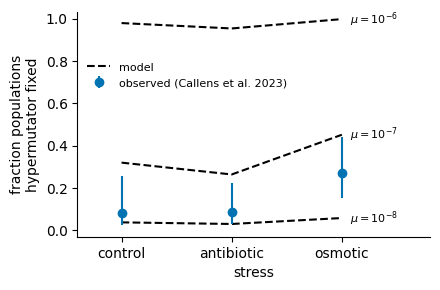

In [ ]:
def plot_fixation_by_stress(
    df_observed: pd.DataFrame, df_model: pd.DataFrame
) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(4.5, 3))
    xs = np.arange(len(stresses))
    ax.errorbar(
        xs,
        df_observed["fraction fixed"],
        yerr=[
            df_observed["fraction fixed"] - df_observed["ci lo"],
            df_observed["ci hi"] - df_observed["fraction fixed"],
        ],
        color=sns.color_palette("colorblind")[0],
        marker="o",
        ls="none",
        label="observed (Callens et al. 2023)",
        zorder=3,
    )
    for mu in mutator_supply_rates:
        ys = (
            df_model[df_model["mutator supply rate"] == mu]
            .set_index("stress")
            .loc[stresses, "fraction fixed"]
        )
        ax.plot(
            xs,
            ys,
            color="black",
            linestyle="--",
            label="model" if mu == mutator_supply_rates[0] else None,
        )
        ax.annotate(
            rf"$\mu = 10^{{{np.log10(mu):.0f}}}$",
            xy=(xs[-1], ys.iloc[-1]),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
        )
    ax.set_xticks(xs)
    ax.set_xticklabels(stresses)
    ax.set_xlim(-0.4, len(stresses) - 0.2)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel("stress")
    ax.set_ylabel("fraction populations\nhypermutator fixed")
    ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(0.0, 0.72))
    sns.despine(fig)
    fig.tight_layout()
    return fig

tp.tee(
    plot_fixation_by_stress,
    df_observed=df_observed,
    df_model=df_model,
    teeplot_subdir=teeplot_subdir,
)

teeplots/callens2023-hypermutator-emergence/viz=plot-fixation-by-sweeps+ext=.pdf
teeplots/callens2023-hypermutator-emergence/viz=plot-fixation-by-sweeps+ext=.png


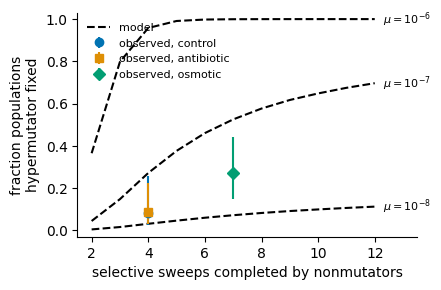

In [ ]:
def plot_fixation_by_sweeps(
    df_observed: pd.DataFrame, df_curve: pd.DataFrame
) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(4.5, 3))
    for mu in mutator_supply_rates:
        curve = df_curve[df_curve["mutator supply rate"] == mu]
        ax.plot(
            curve["num sweeps"],
            curve["fraction fixed"],
            color="black",
            linestyle="--",
            label="model" if mu == mutator_supply_rates[0] else None,
        )
        ax.annotate(
            rf"$\mu = 10^{{{np.log10(mu):.0f}}}$",
            xy=(curve["num sweeps"].iloc[-1], curve["fraction fixed"].iloc[-1]),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
        )
    palette = sns.color_palette("colorblind")
    for (__, row), color, marker in zip(
        df_observed.iterrows(), palette, "osD"
    ):
        ax.errorbar(
            [row["num sweeps"]],
            [row["fraction fixed"]],
            yerr=[
                [row["fraction fixed"] - row["ci lo"]],
                [row["ci hi"] - row["fraction fixed"]],
            ],
            color=color,
            marker=marker,
            ls="none",
            label=f"observed, {row['stress']}",
            zorder=3,
        )
    ax.set_xlim(1.5, 13.5)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel("selective sweeps completed by nonmutators")
    ax.set_ylabel("fraction populations\nhypermutator fixed")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    sns.despine(fig)
    fig.tight_layout()
    return fig

tp.tee(
    plot_fixation_by_sweeps,
    df_observed=df_observed,
    df_curve=df_curve,
    teeplot_subdir=teeplot_subdir,
)

## Timing of Emergence

Observed: transfer at which an IS10 insertion in *mutS* or *mutL* was first detected by PCR, among insertions still present at the end of the experiment.
Model: probability that a hypermutator lineage bound for fixation has taken the lead by a given transfer.
Detection by PCR lags the lead, and IS10 insertion is only one route to hypermutation, so only the shapes are comparable.

In [ ]:
_persisting = df_is10[
    df_is10["first detected transfer"].notna()
    & df_is10["final status"].str.contains("IS")
]
_num_assayed = df_is10.groupby("stress")["population"].nunique()
df_timing_observed = pd.concat(
    [
        pd.DataFrame(
            {
                "stress": stress,
                "transfer": np.sort(group["first detected transfer"]),
                "fraction populations": np.arange(1, len(group) + 1)
                / _num_assayed[stress],
            },
        )
        for stress, group in _persisting.groupby("stress")
    ],
)
_inputs = df_inputs.set_index("stress")
df_timing_model = pd.DataFrame(
    [
        {
            "stress": stress,
            "mutator supply rate": mu,
            "transfer": transfer,
            "fraction populations": calc_denovo_fixprob(
                _inputs.loc[stress, "population size"],
                _inputs.loc[stress, "available beneficial mutations"],
                s=_inputs.loc[stress, "selection strength"],
                mu=mu,
                n_gen=int(transfer * n_gen / 148),
            ),
        }
        for stress in ("antibiotic", "osmotic")
        for mu in mutator_supply_rates
        for transfer in range(20, 149, 16)
    ],
)
df_timing_model

,stress,mutator supply rate,transfer,fraction populations
0,antibiotic,1.000000e-08,20,0.000325
1,antibiotic,1.000000e-08,36,0.000711
2,antibiotic,1.000000e-08,52,0.003175
3,antibiotic,1.000000e-08,68,0.004560
4,antibiotic,1.000000e-08,84,0.010115
...,...,...,...,...
49,osmotic,1.000000e-06,84,0.899567
50,osmotic,1.000000e-06,100,0.959610
51,osmotic,1.000000e-06,116,0.985030
52,osmotic,1.000000e-06,132,0.994611


teeplots/callens2023-hypermutator-emergence/viz=plot-emergence-timing+ext=.pdf
teeplots/callens2023-hypermutator-emergence/viz=plot-emergence-timing+ext=.png


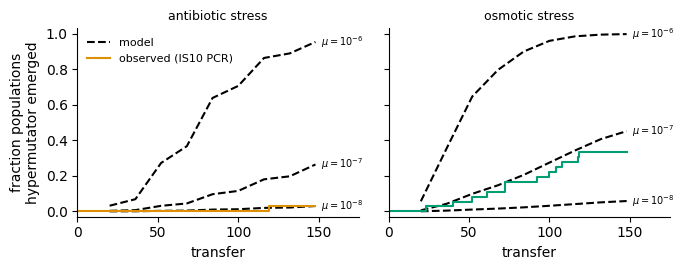

In [ ]:
def plot_emergence_timing(
    df_timing_observed: pd.DataFrame, df_timing_model: pd.DataFrame
) -> plt.Figure:
    fig, axs = plt.subplots(1, 2, figsize=(7, 2.8), sharex=True, sharey=True)
    palette = sns.color_palette("colorblind")
    for ax, stress, color in zip(
        axs, ("antibiotic", "osmotic"), palette[1:]
    ):
        for mu in mutator_supply_rates:
            model = df_timing_model[
                (df_timing_model["stress"] == stress)
                & (df_timing_model["mutator supply rate"] == mu)
            ]
            ax.plot(
                model["transfer"],
                model["fraction populations"],
                color="black",
                linestyle="--",
                label="model" if mu == mutator_supply_rates[0] else None,
            )
            ax.annotate(
                rf"$\mu = 10^{{{np.log10(mu):.0f}}}$",
                xy=(
                    model["transfer"].iloc[-1],
                    model["fraction populations"].iloc[-1],
                ),
                xytext=(4, 0),
                textcoords="offset points",
                va="center",
                fontsize=7,
            )
        observed = df_timing_observed[
            df_timing_observed["stress"] == stress
        ]
        ax.step(
            [0, *observed["transfer"], 148],
            [
                0,
                *observed["fraction populations"],
                observed["fraction populations"].max(),
            ],
            where="post",
            color=color,
            label="observed (IS10 PCR)",
        )
        ax.set_title(f"{stress} stress", fontsize=9)
        ax.set_xlabel("transfer")
        ax.set_xlim(0, 175)
        ax.set_ylim(-0.03, 1.03)
    axs[0].set_ylabel("fraction populations\nhypermutator emerged")
    axs[0].legend(frameon=False, fontsize=8, loc="upper left")
    sns.despine(fig)
    fig.tight_layout()
    return fig

tp.tee(
    plot_emergence_timing,
    df_timing_observed=df_timing_observed,
    df_timing_model=df_timing_model,
    teeplot_subdir=teeplot_subdir,
)